# 06. Проверка исправленной ассоциации на чистом development
 Здесь только пять чистых development-видео: без атак и без обучения. Параметры кандидата уже выбраны на validation и не подбираются по этим результатам. Первый расчёт detections/признаков; затем оба трекера сравниваются на одинаковом кэше.


In [ ]:
import sys, os, subprocess, importlib.util
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules or Path('/content').is_dir()
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/ML6')
else:
    PROJECT = Path('D:/ML6')
RUN_ID = 'blue_aug_20261112_v2'  # одинаковый во всех 10 ноутбуках; старый run не меняем
BUNDLE = PROJECT / 'notebooks_colab_full'
assert (BUNDLE / 'tracking_lab.py').is_file(), BUNDLE
packages = {'scipy':'scipy', 'pandas':'pandas', 'cv2':'opencv-python-headless',
    'matplotlib':'matplotlib', 'tqdm':'tqdm', 'trackeval':'trackeval==1.3.0',
    'cryptography':'cryptography', 'imageio':'imageio', 'imageio_ffmpeg':'imageio-ffmpeg'}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
# Совместимую пару torch/torchvision предоставляет Colab; автоматически её не заменяем.
sys.path.insert(0, str(BUNDLE))
import tracking_lab as tl
assert Path(tl.__file__).resolve() == (BUNDLE / 'tracking_lab.py').resolve(), 'Перезапустите runtime: загружен старый модуль'
assert tl.SCHEMA == 4, 'Перезапустите runtime после обновления исходного кода'
import torch, pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Video, HTML, Image
lab = tl.Lab(PROJECT, RUN_ID)
torch.hub.set_dir(str(PROJECT / 'pretrained_cache'))
display(pd.Series(lab.environment(), name='Среда'))
print('Запуск:', RUN_ID, '| Результаты:', lab.root)

Mounted at /content/drive


,Среда
python,"3.13.16 (main, Oct 1 2026, 15:40:24) [GCC 13...."
packages,"{'torch': '2.14.1+cu130', 'torchvision': '0.29..."
device,cuda
gpu,NVIDIA L4


Запуск: blue_aug_20261112_v2 | Результаты: /content/drive/MyDrive/ML6/runs/blue_aug_20261112_v2


 Основные файлы tracking_lab.py и checkpoints

In [ ]:

from collections import deque
from scipy.optimize import linear_sum_assignment


class SpatialReIDTracker:
    def __init__(self, max_age_seconds=3., min_hits=2, reid_gate=.45, appearance_weight=.25,
                 low_score=.1, high_score=.35, bank_score=.7, bank_margin=.08, bank_size=20,
                 iou_gate=.3):
        self.cfg = dict(max_age_seconds=max_age_seconds, min_hits=min_hits, reid_gate=reid_gate,
                        appearance_weight=appearance_weight, low_score=low_score, high_score=high_score,
                        bank_score=bank_score, bank_margin=bank_margin, bank_size=bank_size,
                        iou_gate=iou_gate)
        self.tracks, self.next_id = {}, 1

    def update(self, boxes, features, scores=None, dt=.2):
        boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
        features = np.asarray(features, dtype=float)
        features = features.reshape(len(boxes), -1) if len(boxes) else np.empty((0, 256))
        scores = np.ones(len(boxes)) if scores is None else np.asarray(scores, dtype=float)
        if not np.isfinite(dt) or dt <= 0:
            raise ValueError('Invalid time step')
        if len(features):
            norms = np.linalg.norm(features, axis=1, keepdims=True)
            if (norms < 1e-8).any() or not np.isfinite(features).all():
                raise ValueError('Invalid appearance features')
            features = features/norms
        if not np.isfinite(boxes).all() or not np.isfinite(scores).all():
            raise ValueError('Invalid detections')
        for key in list(self.tracks):
            self.tracks[key]['age'] += dt
            if self.tracks[key]['age'] > self.cfg['max_age_seconds']:
                del self.tracks[key]
        high = np.flatnonzero(scores >= self.cfg['high_score']).tolist()
        low = np.flatnonzero((scores >= self.cfg['low_score']) & (scores < self.cfg['high_score'])).tolist()
        matched_tracks, matched_boxes = set(), set()
        for indices, appearance in ((high, True), (low, False)):
            ids = [key for key in self.tracks if key not in matched_tracks]
            if not ids or not indices:
                continue
            overlaps = tl.iou_array([self.tracks[key]['bbox'] for key in ids], boxes[indices])
            distances = np.zeros_like(overlaps)
            if appearance and self.cfg['appearance_weight'] > 0:
                for i, key in enumerate(ids):
                    bank = np.asarray(self.tracks[key]['bank'])
                    distances[i] = np.median(1-bank@features[indices].T, axis=0)
                distances = np.clip(distances/2, 0, 1)
            weight = self.cfg['appearance_weight'] if appearance else 0.
            costs = weight*distances + (1-weight)*(1-overlaps)
            costs[overlaps < self.cfg['iou_gate']] = 1e6
            rr, cc = linear_sum_assignment(costs)
            for i, j in zip(rr, cc):
                if costs[i, j] >= 1e5:
                    continue
                key, index = ids[i], indices[j]
                tr = self.tracks[key]
                alternatives = np.r_[np.delete(costs[i], j), np.delete(costs[:, j], i)]
                margin = (float(alternatives.min()) if len(alternatives) else 1e6)-costs[i, j]
                # Update appearance only on an unambiguous, confident observation.
                if (appearance and scores[index] >= self.cfg['bank_score']
                        and margin >= self.cfg['bank_margin'] and costs[i, j] < .4):
                    tr['bank'].append(features[index].copy())
                tr.update(bbox=boxes[index].copy(), score=float(scores[index]), age=0., hits=tr['hits']+1)
                matched_tracks.add(key)
                matched_boxes.add(index)
        for index in high:
            if index in matched_boxes:
                continue
            self.tracks[self.next_id] = dict(bbox=boxes[index].copy(), score=float(scores[index]), age=0.,
                hits=1, bank=deque([features[index].copy()], maxlen=self.cfg['bank_size']))
            self.next_id += 1
        return [dict(track_id=key, bbox=tr['bbox'].tolist(), score=tr['score'])
                for key, tr in self.tracks.items() if tr['age'] == 0 and tr['hits'] >= self.cfg['min_hits']]


def validate_repaired_association(lab):
    variant = tl.load_json(lab.path('configs/selected_variant.json'))['variant']
    rows = tl.load_json(lab.path(f'artifacts/{variant}_tracker_search.json'))
    best = max(rows, key=lambda row: row['score'])
    candidate = int(best['candidate'])
    label = (f"checkpoint_search_{best['detector_checkpoint']}_{candidate % 3}"
             if 'detector_checkpoint' in best else f'tracker_search_{candidate}')
    folder = lab.path(f'artifacts/{label}/{variant}')
    weights, loaded, sources = tl.weight_hashes(lab, variant), {}, {}
    sequences = list(tl.group_sequences(lab.records('val')).items())[:lab.cfg['tracker_val_videos']]
    for video, seq in sequences:
        limit = lab.cfg['tracker_val_frames']
        records = seq if len(seq) <= limit else seq[(len(seq)-limit)//2:][:limit]
        path = folder/'clean'/f'{Path(video).stem}.json'
        saved = tl.load_json(path)
        sources[str(path)] = tl.file_hash(path)
        gt = tl.evaluation_records(lab, records, 'clean')
        if (saved['data_contract'] != tl.digest(records)
                or saved['exact_grid'] != [r['frame_idx'] for r in records]
                or saved['evaluation_gt_contract'] != tl.digest(gt)):
            raise ValueError(f'Changed validation contract: {video}')
        key = tl.inference_contract(lab, records, 'clean', weights)
        items = []
        for index, record in enumerate(tl.tqdm(records, desc=f'Чтение кэша {video}')):
            path = lab.path(f'artifacts/inference_cache/{key}/{index:07d}.json')
            item = tl.load_json(path)
            if (item['contract'] != tl.digest(dict(contract=key, record=record, index=index))
                    or item['frame_idx'] != record['frame_idx']):
                raise ValueError(f'Changed inference cache: {path}')
            items.append(item)
        loaded[video] = (records, gt, saved['records'], items)
    metrics = tl.tracking_metric_objects()
    summary, video_rows, configs = [], [], {}
    # Small predefined comparison. No development/final records are read here.
    for name, weight in [('Исходный', None), ('IoU', 0.), ('Spatial ReID 0.25', .25), ('Spatial ReID 0.5', .5)]:
        raw = {}
        cfg = dict(best['config'])
        if weight is not None:
            cfg.update(appearance_weight=weight, iou_gate=.3)
            configs[name] = cfg
        print('Проверка:', name)
        for video, (records, gt, original, items) in loaded.items():
            if weight is None:
                predictions = original
            else:
                tracker, predictions, previous = SpatialReIDTracker(**cfg), [], None
                for record, reference, item in zip(records, original, items):
                    dt = 1/record['fps'] if previous is None else record['time']-previous
                    previous = record['time']
                    tracks = tracker.update(item['boxes'], item['features'], item['scores'], dt)
                    predictions.append(dict(reference, tracks=tracks))
            data, _ = tl.metric_data(gt, predictions, lab.cfg['score_threshold'])
            raw[video] = {m.get_name(): m.eval_sequence(data) for m in metrics}
            video_rows.append(dict(method=name, video=video, **tl.metric_values(raw[video])))
        combined = {m.get_name(): m.combine_sequences({v: r[m.get_name()] for v, r in raw.items()})
                    for m in metrics}
        summary.append(dict(method=name, **tl.metric_values(combined)))
        display(pd.DataFrame([summary[-1]])[['method', 'HOTA', 'DetA', 'AssA', 'IDF1', 'MOTA', 'IDSW', 'Frag']])
    table = pd.DataFrame(summary)
    expected = pd.read_csv(folder/'aggregate.csv').query("scenario == 'clean'").iloc[0]
    if any(abs(float(table.iloc[0][k])-float(expected[k])) > 1e-6 for k in ('HOTA', 'IDF1', 'MOTA')):
        raise ValueError('Original tracking metrics did not reproduce')
    # Independent IoU implementation must reproduce the completed diagnostic.
    previous = pd.read_csv(lab.path('artifacts/cached_tracker_diagnostics/comparison.csv')).iloc[1]
    if any(abs(float(table.iloc[1][k])-float(previous[k])) > 1e-6 for k in ('HOTA', 'IDF1', 'MOTA')):
        raise ValueError('IoU control did not reproduce')
    winner = max((row for row in summary if row['method'] != 'Исходный'),
                 key=lambda row: (row['HOTA'], row['IDF1']))
    out = lab.path('artifacts/association_repair')
    out.mkdir(parents=True, exist_ok=True)
    table.to_csv(out/'validation.csv', index=False)
    pd.DataFrame(video_rows).to_csv(out/'validation_per_video.csv', index=False)
    (out/'candidate_source.py').write_text(REPAIRED_ASSOCIATION_SOURCE, encoding='utf-8')
    tl.save_json(out/'candidate.json', dict(variant=variant, method=winner['method'],
        tracker=configs[winner['method']], validation_metrics=winner,
        selection_rule='Maximum clean validation HOTA; tie by IDF1; no development/final feedback',
        weights=weights, sources=sources, source_sha256=tl.file_hash(out/'candidate_source.py'),
        context=lab.context(), activated=False))
    display(table[['method', 'HOTA', 'DetA', 'AssA', 'IDF1', 'MOTA', 'IDSW', 'Frag']])
    display(pd.DataFrame(video_rows))
    print('Кандидат для проверки на development:', winner['method'])
    print('Кандидат сохранён отдельно. Рабочая система, веса и прежние настройки не изменены.')
    return table


In [ ]:

import gc
import hashlib
import time


def checked_association_candidate(lab):
    path = lab.path('artifacts/association_repair/candidate.json')
    candidate = tl.load_json(path)
    source = lab.path('artifacts/association_repair/candidate_source.py')
    expected = hashlib.sha256(REPAIRED_ASSOCIATION_SOURCE.encode('utf-8')).hexdigest()
    if tl.file_hash(source) != expected or candidate['source_sha256'] != expected:
        raise ValueError('Код кандидата изменился после validation. Пришлите ошибку; не выбирайте новые параметры по development.')
    selected = tl.load_json(lab.path('configs/selected_variant.json'))['variant']
    if candidate['variant'] != selected or candidate['context'] != lab.context():
        raise ValueError('Изменились выбранная модель, конфигурация или среда')
    if candidate['weights'] != tl.weight_hashes(lab, selected):
        raise ValueError('Веса отличаются от использованных при выборе кандидата')
    return candidate


def reference_spec(lab):
    candidate = checked_association_candidate(lab)
    variant = candidate['variant']
    records = lab.records('dev')
    if not records or any(r['split'] != 'dev' for r in records):
        raise ValueError('Требуется development-выборка')
    tracker = tl.load_json(lab.path(f'configs/{variant}_tracker.json'))
    contract = tl.digest(dict(context=lab.context(), records=records, pixels=lab.input_contract(records),
                              weights=candidate['weights'], tracker=tracker, scenario='clean'))
    folder = lab.path(f'artifacts/association_repair_reference_clean/{variant}')
    marker = folder/'completion.json'
    return candidate, records, tracker, contract, folder, marker


def prepare_clean_development(lab, local_root):
    candidate, records, tracker, contract, folder, marker = reference_spec(lab)
    videos = tl.group_sequences(records)
    names = ['aggregate.csv', 'per_video.csv', *[f'clean/{Path(v).stem}.json' for v in videos]]
    if marker.exists():
        completed = tl.load_json(marker)
        hashes = completed.get('files', {})
        if (completed.get('contract') == contract and completed.get('state') == 'complete'
                and set(hashes) == set(names)
                and all((folder/name).is_file() and tl.file_hash(folder/name) == hashes[name] for name in names)):
            print('Чистый development-кэш и результаты проверены. Повтор моделей не требуется.')
            return pd.read_csv(folder/'aggregate.csv')
    assert lab.device.type == 'cuda', 'Для первого расчёта чистых detections включите GPU'
    print('Только clean. Видео:', len(videos), '| кадров:', len(records), '| выбранная модель:', candidate['variant'])
    tl.cache_frames(lab, local_root, splits=('dev',))
    started = time.perf_counter()
    tl.save_json(marker, dict(state='running', contract=contract))
    detector = reid = None
    try:
        detector = tl.load_model(lab, 'detector', candidate['variant'])
        reid = tl.load_model(lab, 'reid', candidate['variant'])
        aggregate, per_video = tl.evaluate_set(lab, detector, reid, 'dev', ['clean'], tracker,
            candidate['variant'], label='association_repair_reference_clean', weights=candidate['weights'])
        if (set(per_video.video) != set(videos) or len(per_video) != len(videos)
                or set(per_video.scenario) != {'clean'} or len(aggregate) != 1
                or int(aggregate.iloc[0]['frames']) != len(records)):
            raise ValueError('Неполная чистая оценка development')
        if not np.isfinite(aggregate[['HOTA', 'IDF1', 'MOTA']].to_numpy()).all():
            raise ValueError('Некорректные метрики')
        hashes = {name: tl.file_hash(folder/name) for name in names}
        tl.save_json(marker, dict(state='complete', contract=contract, files=hashes,
                                wall_seconds=time.perf_counter()-started))
        display(aggregate)
        print('Подготовка чистых результатов завершена.')
        return aggregate
    finally:
        del detector, reid
        gc.collect()
        torch.cuda.empty_cache()


def compare_clean_development(lab):
    candidate, records, _, contract, folder, marker = reference_spec(lab)
    if not marker.exists() or tl.load_json(marker).get('state') != 'complete':
        raise RuntimeError('Сначала завершите подготовку чистых результатов')
    completed = tl.load_json(marker)
    expected_names = {'aggregate.csv', 'per_video.csv',
                      *[f'clean/{Path(v).stem}.json' for v in tl.group_sequences(records)]}
    if (completed.get('contract') != contract or set(completed.get('files', {})) != expected_names or any(
            not (folder/name).is_file() or tl.file_hash(folder/name) != digest
            for name, digest in completed['files'].items())):
        raise ValueError('Контракт или файлы чистой оценки изменились')
    metrics = tl.tracking_metric_objects()
    raw = {'Исходный': {}, candidate['method']: {}}
    per_video, examples = [], []
    for video, sequence in tl.group_sequences(records).items():
        saved = tl.load_json(folder/'clean'/f'{Path(video).stem}.json')
        gt = tl.evaluation_records(lab, sequence, 'clean')
        if (saved['data_contract'] != tl.digest(sequence)
                or saved['exact_grid'] != [r['frame_idx'] for r in sequence]
                or saved['evaluation_gt_contract'] != tl.digest(gt)):
            raise ValueError(f'Изменились данные: {video}')
        original = saved['records']
        key = tl.inference_contract(lab, sequence, 'clean', candidate['weights'])
        tracker, predictions, previous = SpatialReIDTracker(**candidate['tracker']), [], None
        for index, record in enumerate(tl.tqdm(sequence, desc=f'Кандидат: {video}')):
            item = tl.load_json(lab.path(f'artifacts/inference_cache/{key}/{index:07d}.json'))
            if (item['contract'] != tl.digest(dict(contract=key, record=record, index=index))
                    or item['frame_idx'] != record['frame_idx']):
                raise ValueError('Несовместимый кэш признаков')
            dt = 1/record['fps'] if previous is None else record['time']-previous
            previous = record['time']
            tracks = tracker.update(item['boxes'], item['features'], item['scores'], dt)
            predictions.append(dict(original[index], tracks=tracks))
        for method, pred in [('Исходный', original), (candidate['method'], predictions)]:
            data, _ = tl.metric_data(gt, pred, lab.cfg['score_threshold'])
            raw[method][video] = {m.get_name(): m.eval_sequence(data) for m in metrics}
            per_video.append(dict(method=method, video=video, frames=len(sequence),
                                  **tl.metric_values(raw[method][video])))
        # Save candidate tracks separately for inspection and future visual review.
        out = lab.path('artifacts/association_repair/development_predictions')
        out.mkdir(parents=True, exist_ok=True)
        tl.save_json(out/f'{Path(video).stem}.json', dict(records=predictions, exact_grid=saved['exact_grid'],
                     data_contract=saved['data_contract'], candidate_sha256=candidate['source_sha256']))
        middle = len(sequence)//2
        examples.append((sequence[middle], original[middle], predictions[middle]))
    results = []
    for method, sequences in raw.items():
        combined = {m.get_name(): m.combine_sequences({v: r[m.get_name()] for v, r in sequences.items()})
                    for m in metrics}
        results.append(dict(method=method, **tl.metric_values(combined)))
    table = pd.DataFrame(results)
    expected = pd.read_csv(folder/'aggregate.csv').iloc[0]
    if any(abs(float(table.iloc[0][k])-float(expected[k])) > 1e-6 for k in ('HOTA', 'IDF1', 'MOTA')):
        raise ValueError('Исходная оценка development не воспроизвелась')
    out = lab.path('artifacts/association_repair')
    table.to_csv(out/'development.csv', index=False)
    pd.DataFrame(per_video).to_csv(out/'development_per_video.csv', index=False)
    tl.save_json(out/'development_check.json', dict(complete=True, activated=False,
        candidate_sha256=candidate['source_sha256'], tracker=candidate['tracker'],
        variant=candidate['variant'], reference_contract=contract,
        policy='Fixed validation candidate evaluated on clean development. No tuning or final access.'))
    display(table[['method', 'HOTA', 'DetA', 'AssA', 'IDF1', 'MOTA', 'IDSW', 'Frag']])
    display(pd.DataFrame(per_video))
    return table, examples


def show_clean_development_examples(lab, examples):
    if not hasattr(lab, 'frame_cache_root'):
        return
    from matplotlib.patches import Rectangle
    fig, axes = plt.subplots(len(examples), 2, figsize=(16, 4*len(examples)), squeeze=False)
    for row, (record, original, candidate) in enumerate(examples):
        frame = tl.frame_tensor(lab, record).permute(1, 2, 0).numpy()
        for ax, pred, title in zip(axes[row], (original, candidate), ('Исходный', 'Кандидат')):
            ax.imshow(frame)
            for tr in pred['tracks']:
                x1, y1, x2, y2 = tr['bbox']
                ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor='lime', linewidth=1))
                ax.text(x1, y1, str(tr['track_id']), color='yellow', fontsize=8)
            ax.set_title(f"{record['video']} / {record['frame_idx']} / {title}")
            ax.axis('off')
    plt.tight_layout(); plt.show()


In [ ]:
candidate = checked_association_candidate(lab)
print('Модель:', candidate['variant'], '| Кандидат:', candidate['method'])
display(pd.Series(candidate['tracker']))
print('Development-видео:', len(tl.group_sequences(lab.records('dev'))), '| кадров:', len(lab.records('dev')))


Модель: natural | Кандидат: Spatial ReID 0.5


,0
max_age_seconds,3.00
min_hits,2.00
reid_gate,0.45
appearance_weight,0.50
low_score,0.10
high_score,0.35
bank_score,0.70
bank_margin,0.08
bank_size,20.00
iou_gate,0.30


Development-видео: 5 | кадров: 561


Шаг 1. content восстанавливаются только development-кадры. Считаются clean detections, признаки и исходный трекер. Готовые кадровые результаты используют проверенный кэш при продолжении после сброса. Полностью готовый этап пропускается после проверки контрактов и SHA256 файлов. Уменьшения качества входных изображений или числа кадров нет.

In [ ]:
LOCAL = '/content/ml6_full_frames' if IN_COLAB else str(lab.path('local_frames'))
reference = prepare_clean_development(lab, LOCAL)


Только clean. Видео: 5 | кадров: 561 | выбранная модель: natural


Локальный кэш:   0%|          | 0/131 [00:00<?, ?архив/s]

Архив → /content:   0%|          | 0.00/58.9M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/24.6M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/37.5M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/33.8M [00:00<?, ?B/s]

... (4 outputs left out)

uid_vid_00013.mp4 clean:   0%|          | 0/126 [00:00<?, ?it/s]

uid_vid_00018.mp4 clean:   0%|          | 0/86 [00:00<?, ?it/s]

,scenario,variant,AssA,DetA,HOTA,CLR_TP,CLR_FN,CLR_FP,IDSW,Frag,MOTA,IDF1,AP50,precision,recall,frames,seconds,IDSW_total,FPS
0,clean,natural,0.370145,0.44779,0.401326,9723.0,5286.0,3971.0,1518.0,1204.0,0.282097,0.426297,0.722794,0.779088,0.682124,561,505.536743,1518,1.109712


Подготовка чистых результатов завершена.


Шаг 2. проверка зафиксированного кандидата на тех же detections и признаках. Сравниваются исходный и исправленный трекеры, отдельно по каждому видео и суммарно через TrackEval combine_sequences. Кандидат в рабочую систему автоматически не устанавливается.

In [ ]:
comparison, examples = compare_clean_development(lab)


Кандидат: uid_vid_00008.mp4:   0%|          | 0/167 [00:00<?, ?it/s]

Кандидат: uid_vid_00009.mp4:   0%|          | 0/69 [00:00<?, ?it/s]

Кандидат: uid_vid_00011.mp4:   0%|          | 0/113 [00:00<?, ?it/s]

Кандидат: uid_vid_00013.mp4:   0%|          | 0/126 [00:00<?, ?it/s]

Кандидат: uid_vid_00018.mp4:   0%|          | 0/86 [00:00<?, ?it/s]

,method,HOTA,DetA,AssA,IDF1,MOTA,IDSW,Frag
0,Исходный,0.401326,0.447790,0.370145,0.426297,0.282097,1518.0,1204.0
1,Spatial ReID 0.5,0.427702,0.472852,0.402267,0.454248,0.343727,1013.0,909.0


,method,video,frames,HOTA,DetA,AssA,MOTA,CLR_TP,CLR_FN,CLR_FP,IDSW,Frag,IDF1
0,Исходный,uid_vid_00008.mp4,167,0.188056,0.437129,0.084073,0.053005,1309.0,804.0,442.0,755.0,379.0,0.152174
1,Spatial ReID 0.5,uid_vid_00008.mp4,167,0.209708,0.497680,0.090583,0.267392,1588.0,525.0,589.0,434.0,204.0,0.213520
2,Исходный,uid_vid_00009.mp4,69,0.383784,0.379032,0.394120,0.123678,842.0,387.0,588.0,102.0,115.0,0.445280
3,Spatial ReID 0.5,uid_vid_00009.mp4,69,0.446428,0.405211,0.509938,0.168430,918.0,311.0,637.0,74.0,78.0,0.500000
4,Исходный,uid_vid_00011.mp4,113,0.499325,0.576801,0.435982,0.654291,1310.0,333.0,146.0,89.0,80.0,0.577606
5,Spatial ReID 0.5,uid_vid_00011.mp4,113,0.524937,0.614352,0.450340,0.673767,1332.0,311.0,160.0,65.0,61.0,0.570973
6,Исходный,uid_vid_00013.mp4,126,0.359048,0.408693,0.331557,0.206121,4944.0,3682.0,2625.0,541.0,599.0,0.382464
7,Spatial ReID 0.5,uid_vid_00013.mp4,126,0.395510,0.426281,0.393836,0.251681,5254.0,3372.0,2675.0,408.0,542.0,0.426336
8,Исходный,uid_vid_00018.mp4,86,0.697657,0.671166,0.728327,0.798999,1318.0,80.0,170.0,31.0,31.0,0.859321
9,Spatial ReID 0.5,uid_vid_00018.mp4,86,0.684061,0.679700,0.695186,0.793276,1325.0,73.0,184.0,32.0,24.0,0.798762


Проверка завершена. Кандидат не активирован в 06–09; сначала разбираем эти результаты.


Контрольные кадры: одинаковые изображения, рамки и ID исходного и исправленного трекеров. Это статические примеры; для оценки сохранения ID главным остаётся последовательность и метрики по видео.

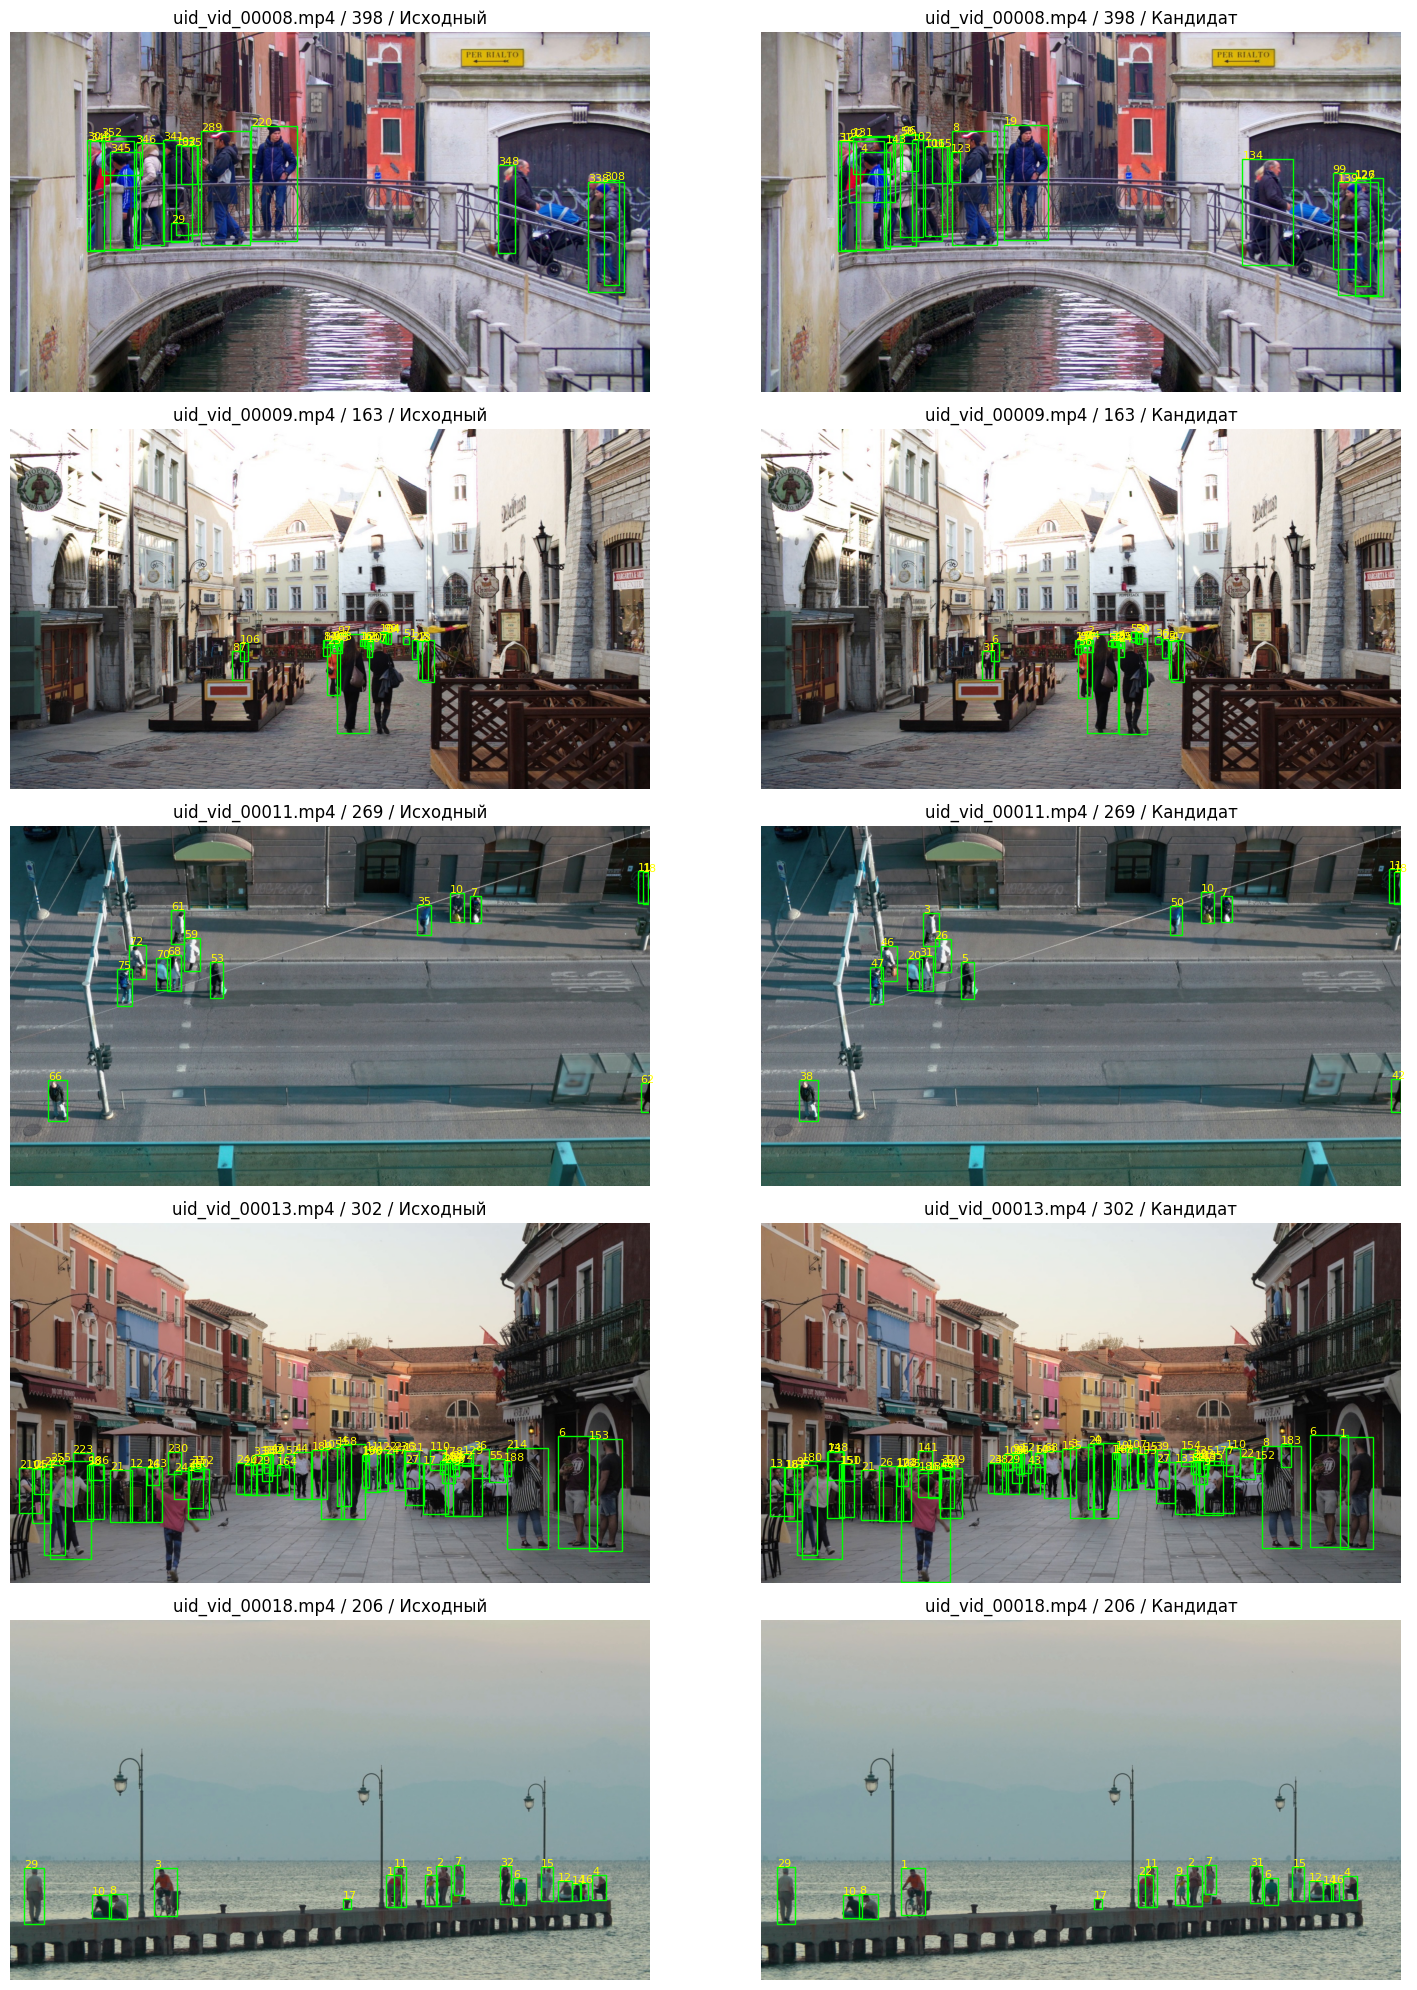

In [ ]:
show_clean_development_examples(lab, examples)


Исправленный трекер дал измеримое улучшение без переобучения моделей.
- HOTA: 0,401 → 0,428, IDF1: 0,426 → 0,454.
- Переключения ID сократились на 33%: 1518 → 1013.
- Разрывы траекторий: 1204 → 909.
- HOTA вырос на 4 из 5 видео, на одном немного снизился.
Проверка выполнена на чистых видео, без атак. Блокнот подтвердил пользу исправления
